# Análisis Exploratorio de Datos (EDA) — Flex Guadalajara Norte
### Tickets de mantenimiento correctivo y tiempo muerto (downtime) del área de Moldeo

## 1. Configuración y carga de datos

In [1]:
import warnings; warnings.filterwarnings('ignore')
import re, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from collections import Counter

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams.update({'figure.figsize': (11, 4.5), 'figure.dpi': 100, 'axes.titleweight': 'bold'})

F_TICKETS  = 'Clasificacion de Tickets 2021.xlsm'
F_DOWNTIME = 'Resumen Downtime Current.xlsx'

for f in (F_TICKETS, F_DOWNTIME):
    print(f, '->', pd.ExcelFile(f).sheet_names)

FileNotFoundError: [Errno 2] No such file or directory: 'Clasificacion de Tickets 2021.xlsm'

Ambos archivos contienen varias hojas. Las hojas `Pivot…`, `Tablas`, `Sheet2`, `Sheet11` y `Catalogo/Catlog` son tablas dinámicas o catálogos derivados de los datos crudos. Las hojas con datos a nivel de registro son:

* **`Data`** (tickets 2025–2026) y **`2020-2021`** (tickets históricos) en el archivo de tickets.
* **`2024`** (eventos de downtime 2025–2026) en el archivo de downtime.

In [ ]:
tk_raw  = pd.read_excel(F_TICKETS,  sheet_name='Data')
old_raw = pd.read_excel(F_TICKETS,  sheet_name='2020-2021')
dt_raw  = pd.read_excel(F_DOWNTIME, sheet_name='2024')
cat_tk  = pd.read_excel(F_TICKETS,  sheet_name='Catalogo', header=None)

for name, d in [('Tickets (Data)', tk_raw), ('Tickets históricos (2020-2021)', old_raw), ('Downtime (2024)', dt_raw)]:
    print(f'{name:32s} filas={d.shape[0]:>6,}  columnas={d.shape[1]}')

Tickets (Data)                   filas=11,150  columnas=42
Tickets históricos (2020-2021)   filas= 1,477  columnas=41
Downtime (2024)                  filas=10,167  columnas=28


## 2. Estructura y calidad de los datos

### 2.1 Perfil de columnas — Tickets (`Data`)

In [ ]:
def perfil(d):
    return pd.DataFrame({
        'tipo': d.dtypes.astype(str),
        '% nulos': (d.isna().mean()*100).round(1),
        'valores únicos': d.nunique(),
        'ejemplo': [str(d[c].dropna().iloc[0])[:45] if d[c].notna().any() else '—' for c in d]
    })
perfil(tk_raw)

,tipo,% nulos,valores únicos,ejemplo
Number,object,0.000,11112,REQ-1761298
State,object,0.000,6,Completed
Equipment Name,object,0.000,887,Robusta
Assigned to,float64,100.000,0,—
Updated,object,22.700,8494,2026-08-24 22:40:13
Opened,datetime64[ns],0.000,11098,2026-08-24 22:36:05
Repair Time,float64,0.000,132,0.5
time 24,object,0.000,4,Completed
Description,object,0.000,9964,Me ayudas con el cierre de maquina robusta no
Requested for,object,0.000,135,Samuel Rodriguez


### 2.2 Perfil de columnas — Downtime (`2024`)

In [ ]:
perfil(dt_raw)

,tipo,% nulos,valores únicos,ejemplo
Equipo,object,0.000,92,Preferida
Opened,datetime64[ns],0.000,10159,2026-08-23 23:50:52.500000
Update,datetime64[ns],0.000,10145,2026-08-24 00:14:31.837000
Reason,object,0.000,4,MANTENIMIENTO - MANTTO. CORRECTIVO
Ticket,object,0.000,5000,REQ-1760551
Downtime,object,0.000,10143,0.3942602783208713
ISSUE 13,object,17.500,95,Mechanical Failure
Description 9,object,17.500,4594,Favor de checar giro intermedio de fin de bra
Work Description (Close Details) 17,object,17.500,3873,Se extrae tonillo capado de sujecion de block
Dia,datetime64[ns],0.000,10159,2026-08-23 23:50:52.500000


### 2.3 Hoja histórica `2020-2021`

In [ ]:
old_raw[['Number','Opened','Problem Category','Class','Location','EQ Type','Day','im']].head(5)

,Number,Opened,Problem Category,Class,Location,EQ Type,Day,im
0,MTNCE00082457,2023-02-28 23:48:09,HABILITACION DE EQUIPO,Otros,Bateria 27 se cambia fusible de 20A danado \nB...,EMBARQUES B5,año 2023 Mes 2,AGV
1,MTNCE00082456,2023-02-28 22:44:36,CONECTOR ELECTRICO DAÑADO/FLOJO,Mecánico,tool room desarmo el conector de 16 pines que ...,La Llorona,año 2023 Mes 2,IMM
2,MTNCE00082455,2023-02-28 21:02:58,CAPACITACION OPERACIONAL(EL EQUIPO NO ESTA FAL...,Operación,equipo funcionando correctamente,Simi,año 2023 Mes 2,Cargador
3,MTNCE00082454,2023-02-28 20:01:08,TUBERIA DAÑADA,Mecánico,SE ENCONTRO VALVULA DE ENFRIAMIENTO CERRADA SE...,Vibora,año 2023 Mes 2,IMM
4,MTNCE00082453,2023-02-28 18:47:02,RESISTENCIA DAÑADA/FLOJA,Eléctrico,SE ENCONTRO CABLE DE RESISTENCIA EN FALSO CONT...,La Llorona,año 2023 Mes 2,IMM


La hoja `Data` (11,150 tickets, ene-2025 → ago-2026) y la hoja `2024` (10,167 paros, mismo periodo) son las fuentes principales.

Observaciones:

* **Columnas vacías o mal nombradas:** `Assigned to`, `Tickets found`, `Total repair time` y `Time of response` están 100% vacías y `time 24` contiene en realidad el estado de asignación y `Eq2` contiene una moneda ("US Dollars"/"Mexican Peso"), no un equipo.
* **Clasificación incompleta:** 23% de los tickets no tiene `Major Code`/`Minor code` ni texto de cierre, y 44% no tiene `Dispositivo`. En Downtime, 17.5% de los eventos no tiene descripción ni clase.
* **Hoja `2020-2021`:** sus columnas están **desplazadas** respecto al encabezado (p. ej. `Location` contiene el texto de cierre y `EQ Type` la ubicación). Se requeriría re-mapearla manualmente; además, su esquema de clasificación es distinto al actual, por lo que se excluye del análisis principal.

### 2.4 Hallazgos de calidad a corregir

In [ ]:
print('Tickets duplicados (Number):', tk_raw['Number'].duplicated().sum())
print('Columnas 100% vacías en Tickets:', [c for c in tk_raw if tk_raw[c].isna().all()])
print('\nDowntime sin número de ticket:')
print(dt_raw.loc[~dt_raw['Ticket'].astype(str).str.startswith('REQ'), 'Ticket'].value_counts())
print('\nValores no numéricos en Downtime:', dt_raw.loc[pd.to_numeric(dt_raw['Downtime'], errors='coerce').isna(), 'Downtime'].unique())
print('\nMarcas con capitalización inconsistente:', sorted(dt_raw['Brand'].dropna().unique()))
print('\nMajor Code con/sin prefijo "B7-" (mismo concepto):')
print(tk_raw['Major Code'].value_counts().loc[lambda s: s.index.str.contains('INJECTION|CLAMPING')])
print('\nClase de falla = 0 (sin clasificar) en Downtime:', (dt_raw['Clase 13'].astype(str)=='0').sum(),
      '| nula:', dt_raw['Clase 13'].isna().sum())

Tickets duplicados (Number): 38
Columnas 100% vacías en Tickets: ['Assigned to', 'Tickets found', 'Total repair time', 'Time of response']

Downtime sin número de ticket:
Ticket
Sin Ticket                                              1115
Sin Ticket - CFE                                         229
Sin Ticket - Falla Suministro electrico                  104
Sin TIcket                                                52
Sin Ticket - Suministro aire Kaeser                       45
                                                        ... 
Sin Ticket - Fuga agua termo                               1
Sin Ticket - Robot levas                                   1
Sin ticket - nozzle heater                                 1
Sin Ticket - Toma de vacio Robot, Tiempo de atencion       1
Sin Ticket - Bomba                                         1
Name: count, Length: 69, dtype: int64

Valores no numéricos en Downtime: ['Sin Ticket']

Marcas con capitalización inconsistente: ['ADVANTAGE', 'ATHENA

In [ ]:
horas = (dt_raw['Update'] - dt_raw['Opened']).dt.total_seconds()/3600
dtn = pd.to_numeric(dt_raw['Downtime'], errors='coerce')
print('Correlación Downtime vs (Update-Opened) en horas:', round(dtn.corr(horas), 5))
print('Diferencia absoluta mediana:', round((dtn - horas).abs().median(), 6), 'h')

Correlación Downtime vs (Update-Opened) en horas: 0.99999
Diferencia absoluta mediana: 0.0 h


**Interpretación.** Se confirma que `Downtime` = horas entre `Opened` y `Update` (correlación ≈ 1). Otras inconsistencias que se corrigen en la limpieza: 38 tickets duplicados, un valor de texto ("Sin Ticket") en una columna numérica, marcas con distinta capitalización (`WITTMANN`/`Wittmann`), el prefijo `B7-` que duplica códigos mayores, y la clase `0` usada como "sin clasificar". También hay ~1,780 paros **sin ticket** (cortes de CFE, suministro eléctrico o de aire), que representan causas externas al equipo.

## 3. Limpieza y preparación

In [ ]:
def norm_txt(s):
    s = str(s).lower()
    s = unicodedata.normalize('NFKD', s).encode('ascii', 'ignore').decode()
    return re.sub(r'\s+', ' ', re.sub(r'[^a-z0-9 ]', ' ', s)).strip()

# Downtime
dt = dt_raw.copy()
dt['Downtime_h'] = pd.to_numeric(dt['Downtime'], errors='coerce')
dt = dt.dropna(subset=['Downtime_h'])
dt['Brand'] = dt['Brand'].str.upper().str.strip()
dt['Tipo_equipo'] = dt['Equipo 26'].replace({0: 'Sin clasificar', '0': 'Sin clasificar'}).fillna('Sin clasificar')
dt['Clase_falla'] = dt['Clase 13'].replace({0: 'Sin clasificar', '0': 'Sin clasificar'}).fillna('Sin clasificar')
dt['Con_ticket'] = dt['Ticket'].astype(str).str.startswith('REQ')
dt['Mes'] = dt['Opened'].dt.to_period('M')
dt['Hora'] = dt['Opened'].dt.hour
dt['DiaSemana'] = dt['Opened'].dt.dayofweek
dt['Turno'] = pd.cut(dt['Hora'], [-1, 6, 14, 22, 24], labels=['3er (22-7)', '1er (7-15)', '2do (15-23)', '3er (22-7) ']).astype(str).str.strip()

# Tickets
tk = tk_raw.drop(columns=[c for c in tk_raw if tk_raw[c].isna().all()] + ['Class3', 'Eq2 - Workgroup'])
tk = tk.drop_duplicates(subset='Number')
tk['Major_norm'] = tk['Major Code'].str.replace(r'^B7-', '', regex=True).str.strip().str.upper()
tk['Minor code'] = tk['Minor code'].fillna('Sin clasificar')
tk['EQ Type'] = tk['EQ Type'].fillna('Sin clasificar')
tk['Mes'] = tk['Opened'].dt.to_period('M')
tk['Hora'] = tk['Opened'].dt.hour
tk['texto'] = tk['Description'].fillna('').astype(str)
tk['texto_cierre'] = tk['Work Description (Close Details)'].fillna('').astype(str)
tk['len_desc'] = tk['texto'].str.split().str.len()
tk['len_cierre'] = tk['texto_cierre'].str.split().str.len()

print('Downtime limpio:', dt.shape, '| periodo', dt.Opened.min().date(), '→', dt.Opened.max().date())
print('Tickets limpio :', tk.shape, '| periodo', tk.Opened.min().date(), '→', tk.Opened.max().date())

Downtime limpio: (10166, 36) | periodo 2025-01-02 → 2026-08-23
Tickets limpio : (11112, 43) | periodo 2025-01-01 → 2026-08-24


## 4. Análisis del tiempo muerto (Downtime)

### 4.1 Distribución de la duración de los paros

                  count  mean   std   min   25%   50%   75%   90%   95%   99%    max
Downtime (h) 10,166.000 1.010 2.210 0.000 0.109 0.394 1.052 2.447 3.882 8.947 67.825

Horas totales de paro: 10,264 h  |  eventos: 10,166


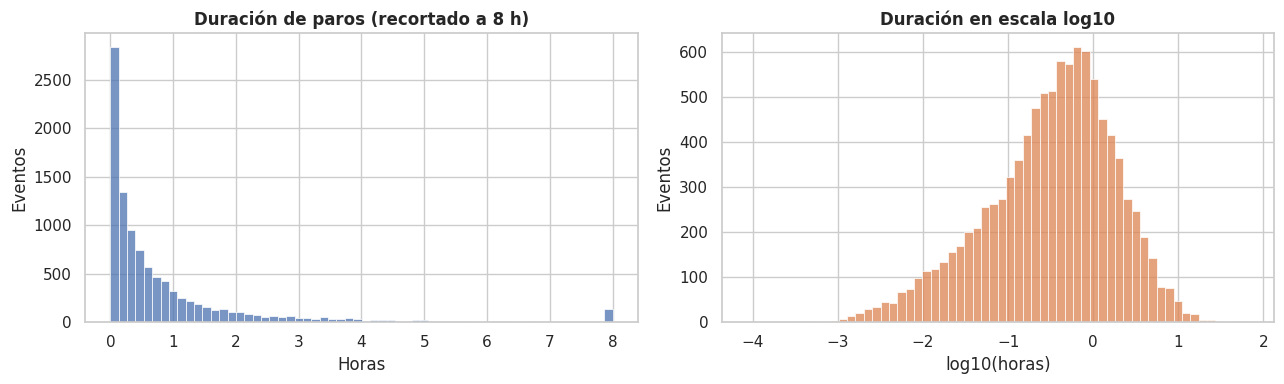

In [ ]:
print(dt['Downtime_h'].describe(percentiles=[.25,.5,.75,.9,.95,.99]).to_frame('Downtime (h)').T)
print(f"\nHoras totales de paro: {dt['Downtime_h'].sum():,.0f} h  |  eventos: {len(dt):,}")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(dt['Downtime_h'].clip(upper=8), bins=60, ax=ax[0], color='#4C72B0')
ax[0].set(title='Duración de paros (recortado a 8 h)', xlabel='Horas', ylabel='Eventos')
sns.histplot(np.log10(dt['Downtime_h']), bins=60, ax=ax[1], color='#DD8452')
ax[1].set(title='Duración en escala log10', xlabel='log10(horas)', ylabel='Eventos')
plt.tight_layout(); plt.show()

In [ ]:
# Concentración: ¿qué % del tiempo muerto explican los paros más largos?
s = dt['Downtime_h'].sort_values(ascending=False).reset_index(drop=True)
for p in (0.05, 0.10, 0.20):
    n = int(len(s)*p)
    print(f'El {p:.0%} de paros más largos ( >{s.iloc[n]:.2f} h ) explica el {s.iloc[:n].sum()/s.sum():.1%} del downtime total')

El 5% de paros más largos ( >3.88 h ) explica el 37.6% del downtime total
El 10% de paros más largos ( >2.45 h ) explica el 52.9% del downtime total
El 20% de paros más largos ( >1.33 h ) explica el 70.7% del downtime total


**Interpretación:** La duración de los paros tiene una distribución fuertemente sesgada a la derecha, la mediana es de 24 minutos (0.39 h) pero la media es 1 h y el máximo 68 h. La concentración es alta: el 10% de los paros más largos explica más de la mitad de las horas perdidas.

 **Implicación para el modelado:** usar transformación logarítmica en la variable objetivo, métricas robustas (MAE, mediana) y considerar un enfoque en dos partes (¿será un paro largo? → ¿cuánto durará?).

### 4.2 Downtime por tipo de equipo

,eventos,horas,mediana,media,% horas
Tipo_equipo,,,,,
IMM,5056,"5,349.690",0.411,1.058,52.120
Robot,2050,"2,036.438",0.417,0.993,19.840
Termoregulador,456,655.963,0.781,1.439,6.391
Secador,458,553.517,0.338,1.209,5.393
Sin clasificar,1116,551.472,0.198,0.494,5.373
Blender,345,274.816,0.420,0.797,2.677
Fixture,142,174.321,0.658,1.228,1.698
Cargador,224,162.799,0.355,0.727,1.586
Controlador,100,73.012,0.328,0.730,0.711


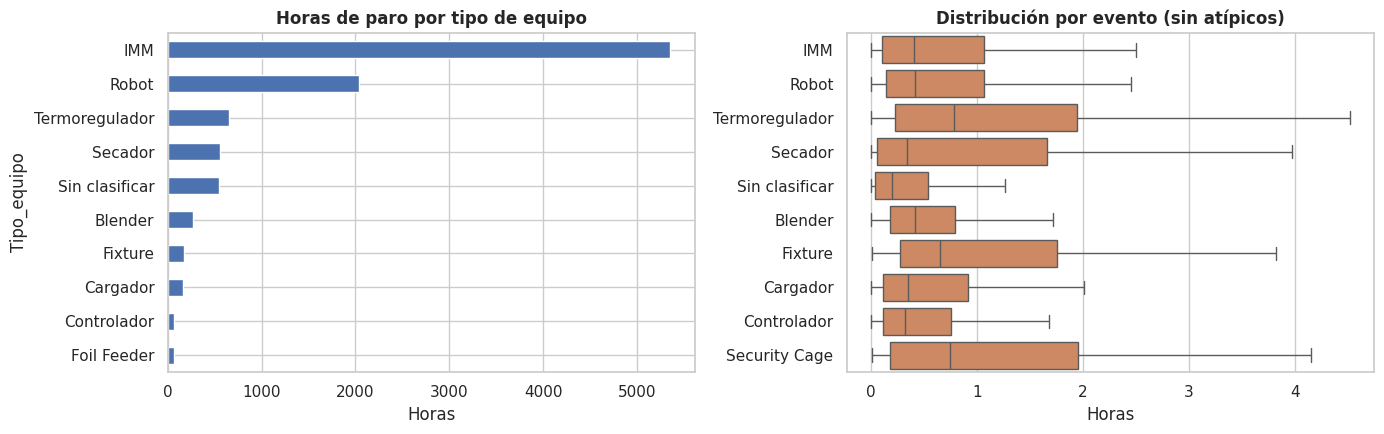

In [ ]:
g = dt.groupby('Tipo_equipo')['Downtime_h'].agg(eventos='count', horas='sum', mediana='median', media='mean').sort_values('horas', ascending=False)
g['% horas'] = g['horas']/g['horas'].sum()*100
display(g.head(12))
top = g[g.eventos >= 30].head(10).index   # boxplot solo para tipos con ≥30 eventos
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
g.head(10)['horas'].plot.barh(ax=ax[0], color='#4C72B0'); ax[0].invert_yaxis(); ax[0].set(title='Horas de paro por tipo de equipo', xlabel='Horas')
sns.boxplot(data=dt[dt.Tipo_equipo.isin(top)], y='Tipo_equipo', x='Downtime_h', order=top, ax=ax[1], showfliers=False, color='#DD8452')
ax[1].set(title='Distribución por evento (sin atípicos)', xlabel='Horas', ylabel='')
plt.tight_layout(); plt.show()

**Interpretación:** Las máquinas de inyección (IMM) concentran 52% de las horas de paro y los **robots** 20%, juntos explican casi tres cuartas partes del tiempo muerto. Los termorreguladores tienen menos eventos, pero su mediana por evento es la más alta (0.8 h), es decir, fallan menos pero tardan más en recuperarse. El grupo "Sin clasificar" (5%) confirma la necesidad de mejorar la captura del tipo de equipo.

### 4.3 Pareto de máquinas (equipo individual)

92 máquinas; 55 (60%) concentran el 80% del downtime


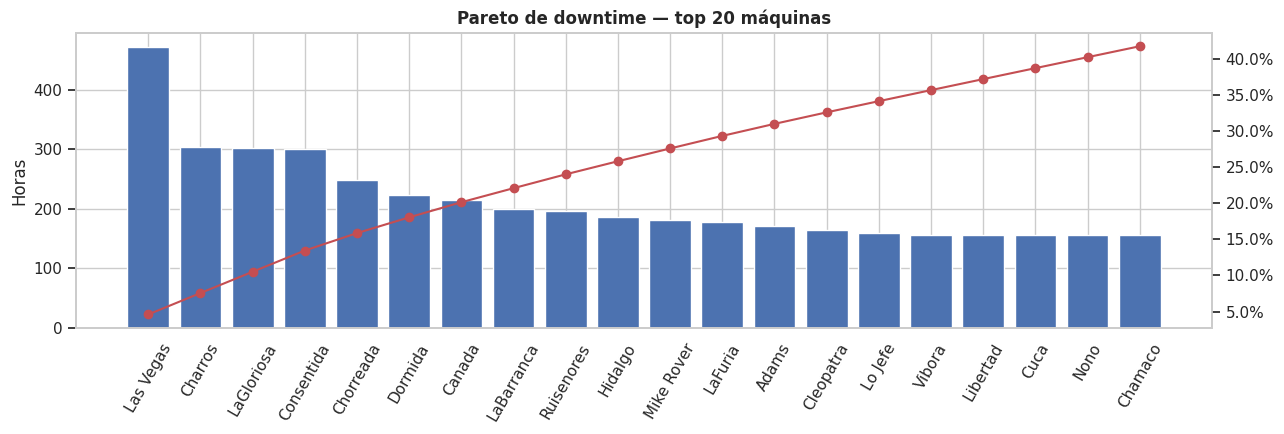

,eventos,horas,% acum
Equipo,,,
Las Vegas,389,472.123,4.600
Charros,175,304.358,7.565
LaGloriosa,281,302.454,10.512
Consentida,260,301.317,13.447
Chorreada,235,248.131,15.865
Dormida,175,223.894,18.046
Canada,154,214.702,20.138
LaBarranca,518,199.404,22.080
Ruisenores,133,196.835,23.998


In [ ]:
pm = dt.groupby('Equipo')['Downtime_h'].agg(eventos='count', horas='sum').sort_values('horas', ascending=False)
pm['% acum'] = pm['horas'].cumsum()/pm['horas'].sum()*100
n80 = (pm['% acum'] <= 80).sum() + 1
print(f'{len(pm)} máquinas; {n80} ({n80/len(pm):.0%}) concentran el 80% del downtime')
top20 = pm.head(20)
fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(top20.index, top20['horas'], color='#4C72B0'); ax.tick_params(axis='x', rotation=60)
ax2 = ax.twinx(); ax2.plot(top20.index, top20['% acum'], color='#C44E52', marker='o'); ax2.yaxis.set_major_formatter(mtick.PercentFormatter()); ax2.grid(False)
ax.set(title='Pareto de downtime — top 20 máquinas', ylabel='Horas'); plt.tight_layout(); plt.show()
top20.head(10)

**Interpretación.** El downtime está **repartido** entre muchas máquinas: 55 de 92 equipos (60%) acumulan el 80% de las horas, por lo que no es un Pareto 80/20 clásico. Sin embargo, *Las Vegas* destaca claramente (472 h, 4.6% del total). También se observan dos perfiles distintos: máquinas con muchos paros cortos, por ejemplo LaBarranca tiene 518 eventos pero solo 0.4 h promedio y tambien hay máquinas con pocos paros pero largos por ejemplo Hidalgo y Charros. Ambos perfiles requieren estrategias diferentes (causa raíz recurrente vs disponibilidad de refacciones/diagnóstico).

### 4.4 Downtime por clase de falla

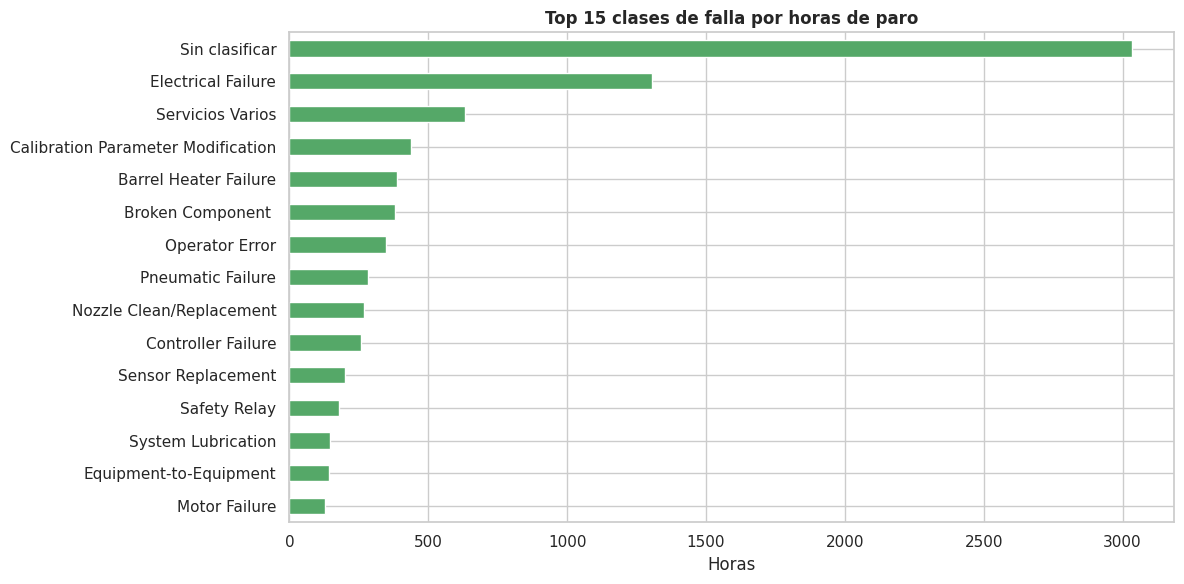

,eventos,horas,mediana,% horas
Clase_falla,,,,
Sin clasificar,3385,"3,033.412",0.368,29.553
Electrical Failure,1282,"1,305.274",0.410,12.717
Servicios Varios,516,631.941,0.317,6.157
Calibration Parameter Modification,440,438.787,0.199,4.275
Barrel Heater Failure,320,385.694,0.627,3.758
Broken Component,273,380.668,0.668,3.709
Operator Error,457,349.178,0.306,3.402
Pneumatic Failure,346,282.724,0.529,2.754
Nozzle Clean/Replacement,225,267.763,0.561,2.609


In [ ]:
cf = dt.groupby('Clase_falla')['Downtime_h'].agg(eventos='count', horas='sum', mediana='median').sort_values('horas', ascending=False)
cf['% horas'] = cf['horas']/cf['horas'].sum()*100
fig, ax = plt.subplots(figsize=(12, 6))
cf.head(15)['horas'].plot.barh(ax=ax, color='#55A868'); ax.invert_yaxis()
ax.set(title='Top 15 clases de falla por horas de paro', xlabel='Horas', ylabel='')
plt.tight_layout(); plt.show()
cf.head(15)

**Interpretación:** La categoría más grande es **"Sin clasificar"**: casi un tercio del tiempo muerto no tiene causa registrada, lo que es la principal área de oportunidad para un modelo que clasifique automáticamente a partir del texto. Entre las causas conocidas dominan las **fallas eléctricas** (13%), seguidas de "Servicios Varios" (categoría genérica poco informativa), ajuste de parámetros y resistencias del barril. Las fallas de componentes físicos (resistencias, componentes rotos, sensores, motores) tienen medianas por evento más altas (0.6–0.7 h).

### 4.5 Motivo del paro, marca del equipo y tickets

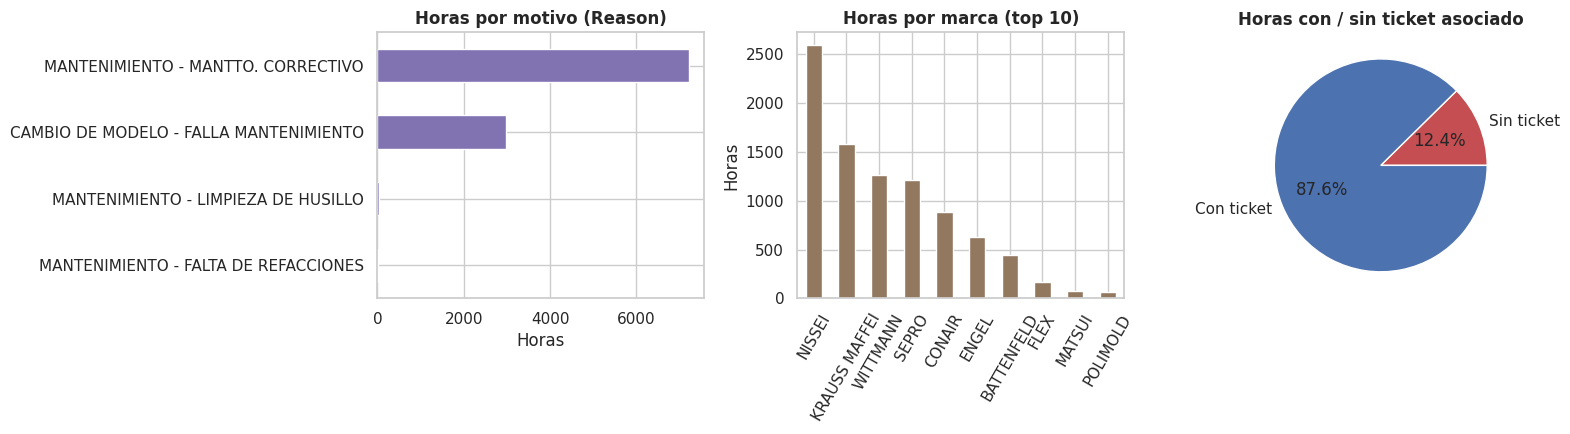

                                        eventos     horas  mediana
Reason                                                            
CAMBIO DE MODELO - FALLA MANTENIMIENTO     2201 2,987.251    0.658
MANTENIMIENTO - FALTA DE REFACCIONES         44    23.987    0.247
MANTENIMIENTO - LIMPIEZA DE HUSILLO          31    46.539    0.779
MANTENIMIENTO - MANTTO. CORRECTIVO         7890 7,206.450    0.342


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
r = dt.groupby('Reason')['Downtime_h'].sum().sort_values()
r.plot.barh(ax=ax[0], color='#8172B2'); ax[0].set(title='Horas por motivo (Reason)', xlabel='Horas', ylabel='')
b = dt.groupby('Brand')['Downtime_h'].agg(['sum','count']).sort_values('sum', ascending=False).head(10)
b['sum'].plot.bar(ax=ax[1], color='#937860'); ax[1].set(title='Horas por marca (top 10)', ylabel='Horas', xlabel=''); ax[1].tick_params(axis='x', rotation=60)
dt.groupby('Con_ticket')['Downtime_h'].sum().rename({True:'Con ticket', False:'Sin ticket'}).plot.pie(ax=ax[2], autopct='%1.1f%%', colors=['#C44E52','#4C72B0'])
ax[2].set(title='Horas con / sin ticket asociado', ylabel='')
plt.tight_layout(); plt.show()
print(dt.groupby('Reason')['Downtime_h'].agg(eventos='count', horas='sum', mediana='median'))

**Interpretación:** El 29% de las horas de paro ocurre durante **cambios de modelo** ("CAMBIO DE MODELO – FALLA MANTENIMIENTO"), con una mediana de 0.66 h por evento, casi el doble que el correctivo normal (0.34 h). Esto sugiere que las fallas asociadas a cambios de molde son un foco relevante. Por marca, **Nissei** acumula más horas (es también la marca con más máquinas/eventos), por lo que conviene normalizar por número de equipos antes de compararlas. El 12% de las horas no tiene ticket, lo que limita la trazabilidad.

### 4.6 Comportamiento temporal

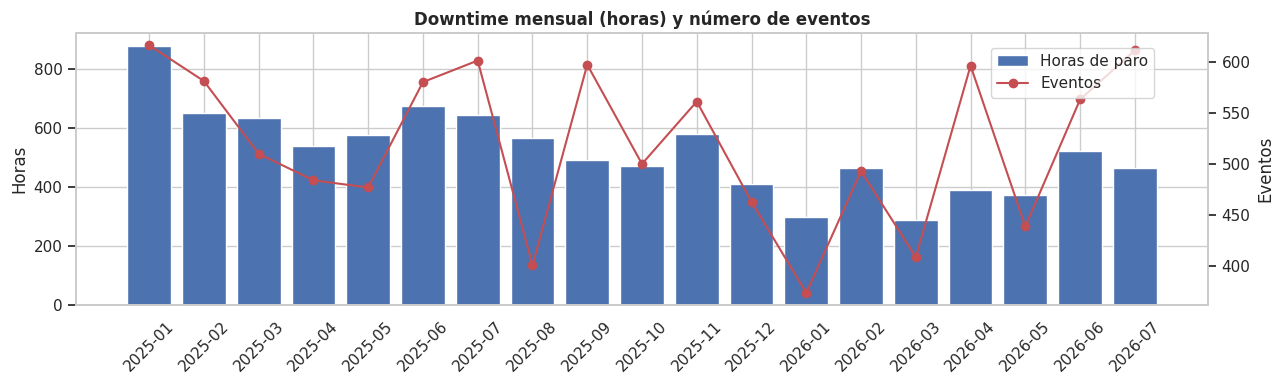

Correlación eventos vs horas por mes: 0.581


In [ ]:
m = dt.groupby('Mes')['Downtime_h'].agg(eventos='count', horas='sum')
m = m.iloc[:-1] if dt.Opened.max().day < 28 else m   # se excluye el último mes si está incompleto
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(m.index.astype(str), m['horas'], color='#4C72B0', label='Horas de paro'); ax.tick_params(axis='x', rotation=45)
ax2 = ax.twinx(); ax2.plot(m.index.astype(str), m['eventos'], color='#C44E52', marker='o', label='Eventos'); ax2.grid(False)
ax.set(title='Downtime mensual (horas) y número de eventos', ylabel='Horas'); ax2.set_ylabel('Eventos')
fig.legend(loc='upper right', bbox_to_anchor=(0.9, 0.88)); plt.tight_layout(); plt.show()
print('Correlación eventos vs horas por mes:', round(m['eventos'].corr(m['horas']), 3))

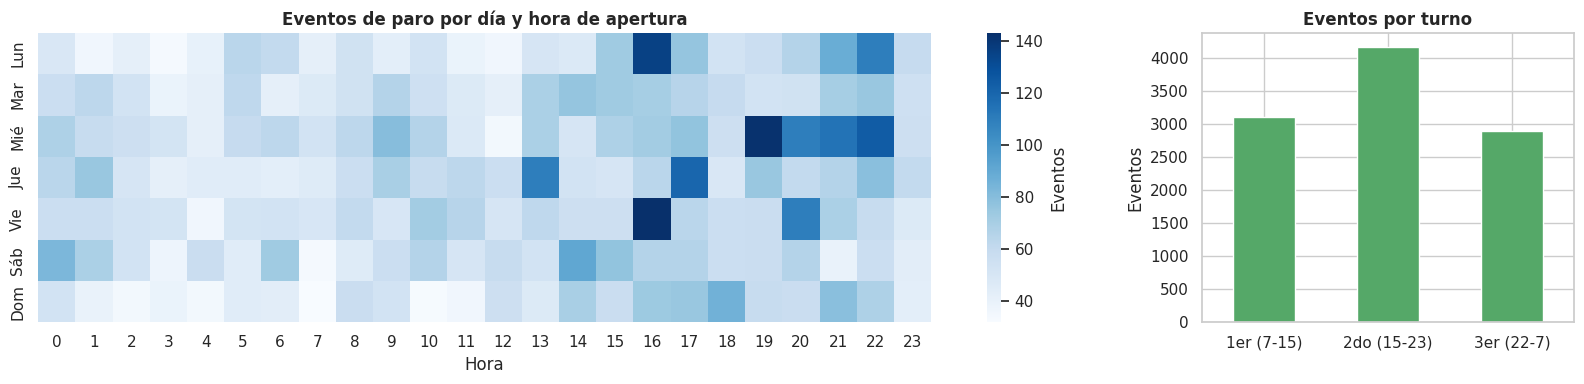

In [ ]:
dias = ['Lun','Mar','Mié','Jue','Vie','Sáb','Dom']
pv = dt.pivot_table(index='DiaSemana', columns='Hora', values='Downtime_h', aggfunc='count').rename(index=dict(enumerate(dias)))
fig, ax = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={'width_ratios': [3, 1]})
sns.heatmap(pv, cmap='Blues', ax=ax[0], cbar_kws={'label': 'Eventos'}); ax[0].set(title='Eventos de paro por día y hora de apertura', xlabel='Hora', ylabel='')
dt.groupby('Turno')['Downtime_h'].agg(['count']).plot.bar(ax=ax[1], legend=False, color='#55A868'); ax[1].set(title='Eventos por turno', xlabel='', ylabel='Eventos'); ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

**Interpretación:** Las horas de paro muestran una tendencia descendente: de 600–870 h/mes a inicios de 2025 a 300–500 h/mes en 2026, aun cuando el número de eventos se mantiene relativamente estable (correlación mensual eventos-horas de solo 0.58). Es decir, los paros son cada vez más cortos, posiblemente por mejoras en la respuesta de mantenimiento. Por hora, los paros se concentran en la tarde-noche (16:00–22:00) y el **2º turno** registra más eventos que el 1º y 3º, no hay un día de la semana claramente dominante. El último mes se excluye de la gráfica por estar incompleto.

## 5. Análisis de los tickets de mantenimiento

### 5.1 Volumen, estado y severidad

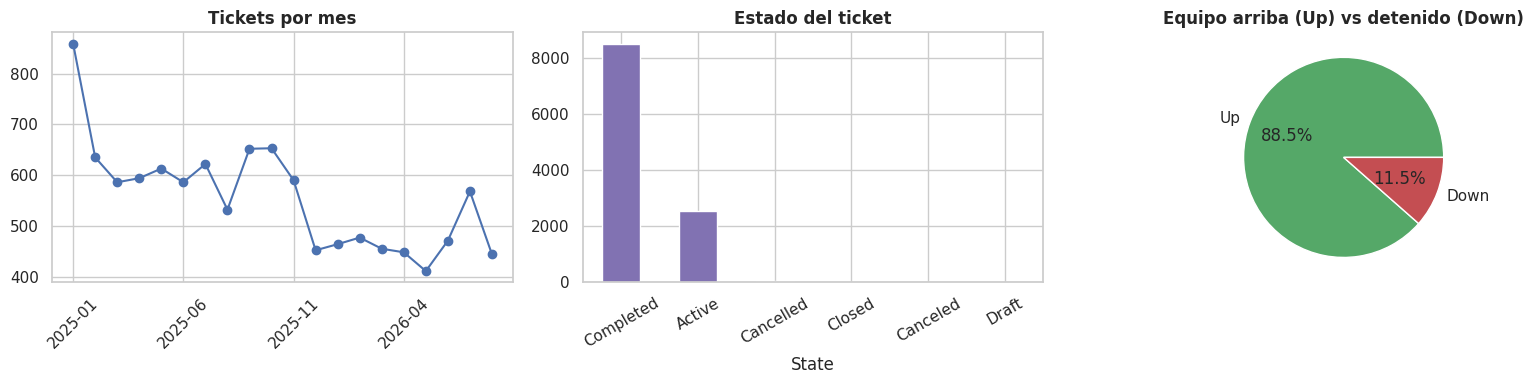

Functional area
Moldeo                     10818
Operaciones Secundarias      145
Tool Room                    141
GDL B7                         2
FLEXTRONICS                    1
Name: count, dtype: int64


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
mt = tk.groupby('Mes').size(); mt.index = mt.index.astype(str)
mt.plot(ax=ax[0], marker='o'); ax[0].set(title='Tickets por mes', xlabel=''); ax[0].tick_params(axis='x', rotation=45)
tk['State'].value_counts().plot.bar(ax=ax[1], color='#8172B2'); ax[1].set(title='Estado del ticket'); ax[1].tick_params(axis='x', rotation=30)
tk['Problem Type'].value_counts().plot.pie(ax=ax[2], autopct='%1.1f%%', colors=['#55A868','#C44E52']); ax[2].set(title='Equipo arriba (Up) vs detenido (Down)', ylabel='')
plt.tight_layout(); plt.show()
print(tk['Functional area'].value_counts())

### 5.2 Tiempo de reparación

                     count  mean   std   min   50%   75%   90%   95%   99%    max
Repair Time (h) 11,109.000 1.198 2.005 0.000 0.500 1.250 3.000 4.750 9.500 37.000


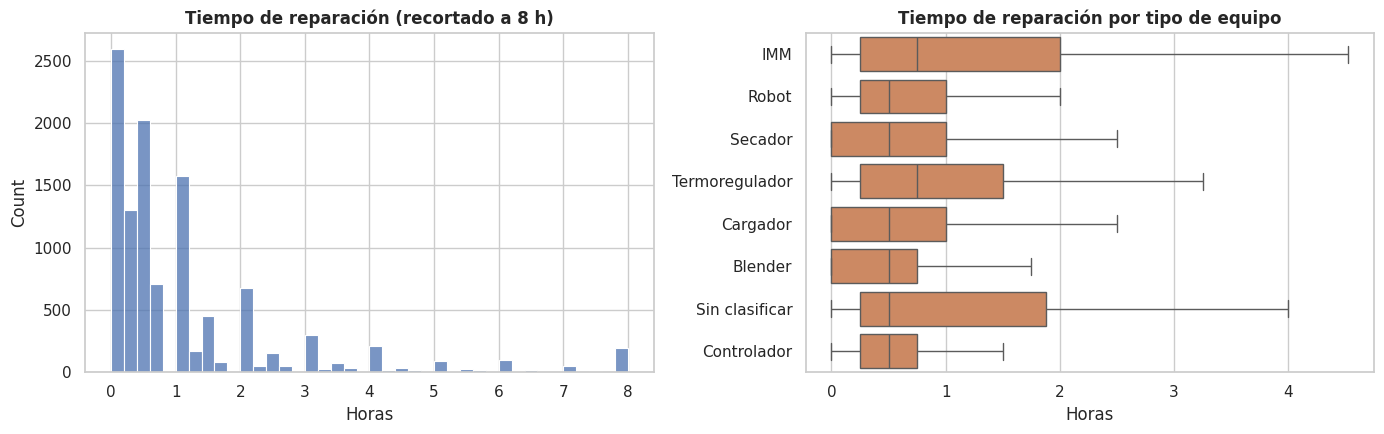

Valores más frecuentes de Repair Time: {0.0: 2564, 0.5: 2020, 1.0: 1570, 0.25: 1301, 0.75: 709, 2.0: 679}


In [ ]:
print(tk['Repair Time'].describe(percentiles=[.5,.75,.9,.95,.99]).to_frame('Repair Time (h)').T)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(tk['Repair Time'].clip(upper=8), bins=40, ax=ax[0]); ax[0].set(title='Tiempo de reparación (recortado a 8 h)', xlabel='Horas')
top_eq = tk['EQ Type'].value_counts().head(8).index
sns.boxplot(data=tk[tk['EQ Type'].isin(top_eq)], x='Repair Time', y='EQ Type', order=top_eq, showfliers=False, ax=ax[1], color='#DD8452')
ax[1].set(title='Tiempo de reparación por tipo de equipo', xlabel='Horas', ylabel='')
plt.tight_layout(); plt.show()
print('Valores más frecuentes de Repair Time:', tk['Repair Time'].value_counts().head(6).to_dict())

In [ ]:
t = tk.groupby('Problem Type').agg(tickets=('Number','count'), repair_prom_h=('Repair Time','mean'), downtime_prom_h=('Downtime','mean'), pct_con_downtime=('Downtime', lambda s: (s>0).mean()*100))
print('Comparación Up vs Down:'); print(t)
c = tk[tk['Downtime']>0]
print('\nCorrelación Repair Time vs Downtime (tickets con paro):', round(c['Repair Time'].corr(c['Downtime']), 3),
      '| Spearman:', round(c['Repair Time'].corr(c['Downtime'], method='spearman'), 3))

Comparación Up vs Down:
              tickets  repair_prom_h  downtime_prom_h  pct_con_downtime
Problem Type                                                           
Down             1277          1.246            0.667            42.678
Up               9825          1.191            0.827            44.601

Correlación Repair Time vs Downtime (tickets con paro): 0.34 | Spearman: 0.321


**Interpretación:** El tiempo de reparación (`Repair Time`) es un valor **capturado manualmente y redondeado** a múltiplos de 15 min, el 23% tiene valor 0, lo que indica que no siempre se registra. Sólo ~44% de los tickets tiene downtime asociado y la correlación entre `Repair Time` y `Downtime` es débil (Spearman ≈ 0.32), por lo que miden cosas distintas (tiempo de trabajo del técnico vs. tiempo que la máquina estuvo parada). Además la etiqueta `Problem Type` (Up/Down) **no discrimina** porque los tickets "Down" no tienen más downtime que los "Up", así que no es confiable como indicador de severidad.

### 5.3 Clasificación de fallas (códigos mayor y menor)

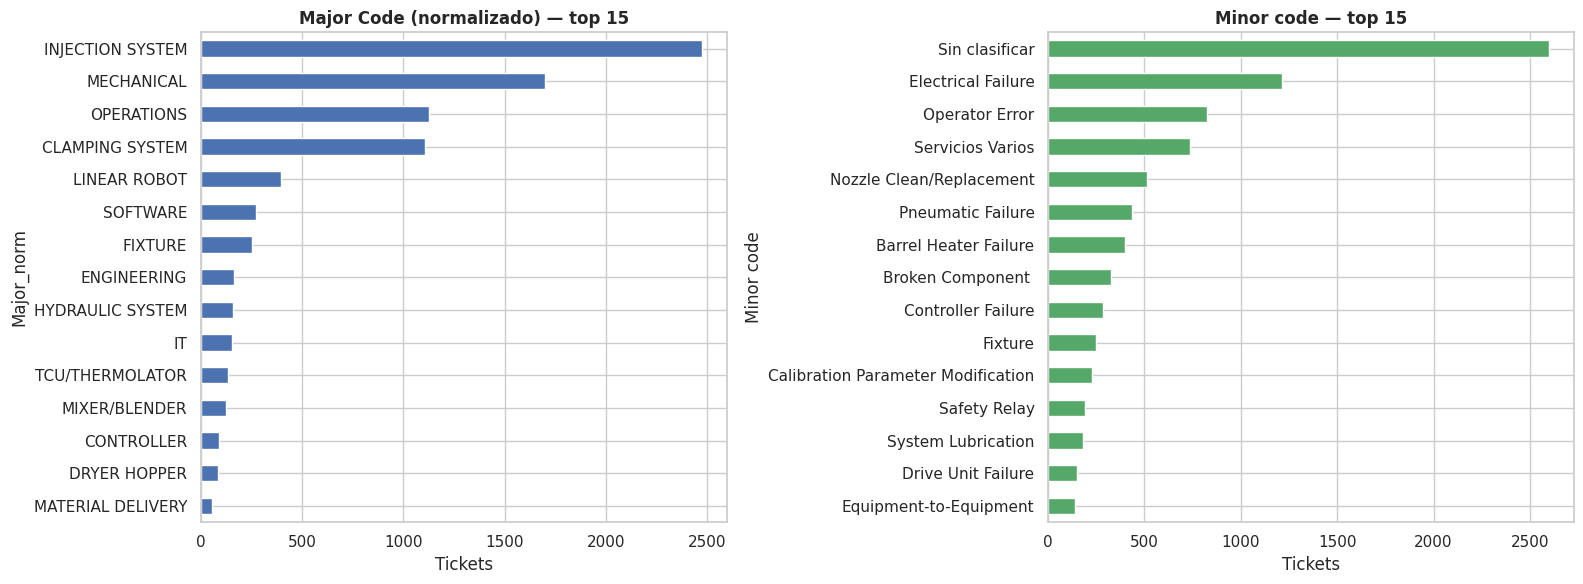

Tickets sin Minor code: 23.4%  |  sin Dispositivo: 44.1%
Categorías distintas de Minor code: 109 | de Dispositivo: 557


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
tk['Major_norm'].value_counts().head(15).plot.barh(ax=ax[0], color='#4C72B0'); ax[0].invert_yaxis(); ax[0].set(title='Major Code (normalizado) — top 15', xlabel='Tickets')
tk['Minor code'].value_counts().head(15).plot.barh(ax=ax[1], color='#55A868'); ax[1].invert_yaxis(); ax[1].set(title='Minor code — top 15', xlabel='Tickets')
plt.tight_layout(); plt.show()
print(f"Tickets sin Minor code: {(tk['Minor code']=='Sin clasificar').mean():.1%}  |  sin Dispositivo: {tk['Dispositivo'].isna().mean():.1%}")
print('Categorías distintas de Minor code:', tk['Minor code'].nunique(), '| de Dispositivo:', tk['Dispositivo'].nunique())

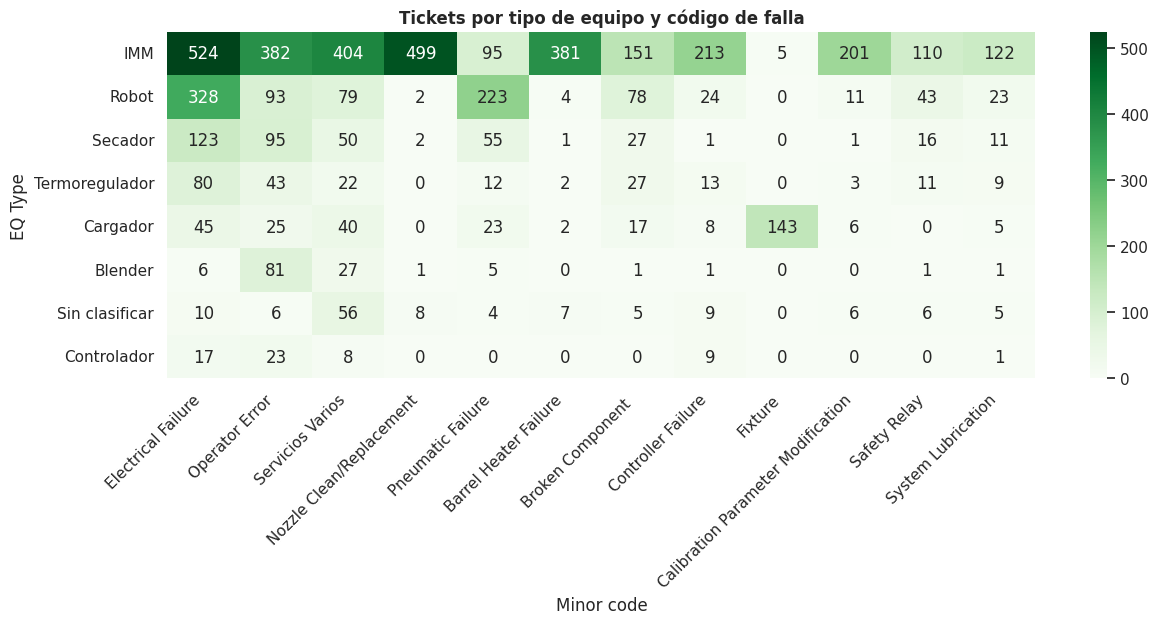

In [ ]:
# Matriz tipo de equipo × código menor (top)
ct = pd.crosstab(tk['EQ Type'], tk['Minor code'])
ct = ct.loc[tk['EQ Type'].value_counts().head(8).index, tk['Minor code'].value_counts().drop('Sin clasificar').head(12).index]
plt.figure(figsize=(14, 4.5)); sns.heatmap(ct, annot=True, fmt='d', cmap='Greens'); plt.title('Tickets por tipo de equipo y código de falla'); plt.xticks(rotation=45, ha='right'); plt.show()

**Interpretación:** Tras normalizar el prefijo `B7-`, los códigos mayores más frecuentes son sistema de inyección, mecánico, operaciones y sistema de cierre. El `Minor code` tiene 109 categorías y el `Dispositivo` 557, con una distribución de cola larga y muchas categorías con muy pocos ejemplos. La matriz equipo × falla muestra patrones coherentes por ejemplo *Pneumatic Failure* se asocia a robots, *Fixture* a cargadores, *Nozzle/Barrel Heater* a IMM, lo que indica que el tipo de equipo es un buen predictor complementario al texto. También se observa que "Operator Error" es frecuente en blenders y secadores, sugiriendo necesidades de capacitación.

### 5.4 Solicitantes y equipos con más tickets

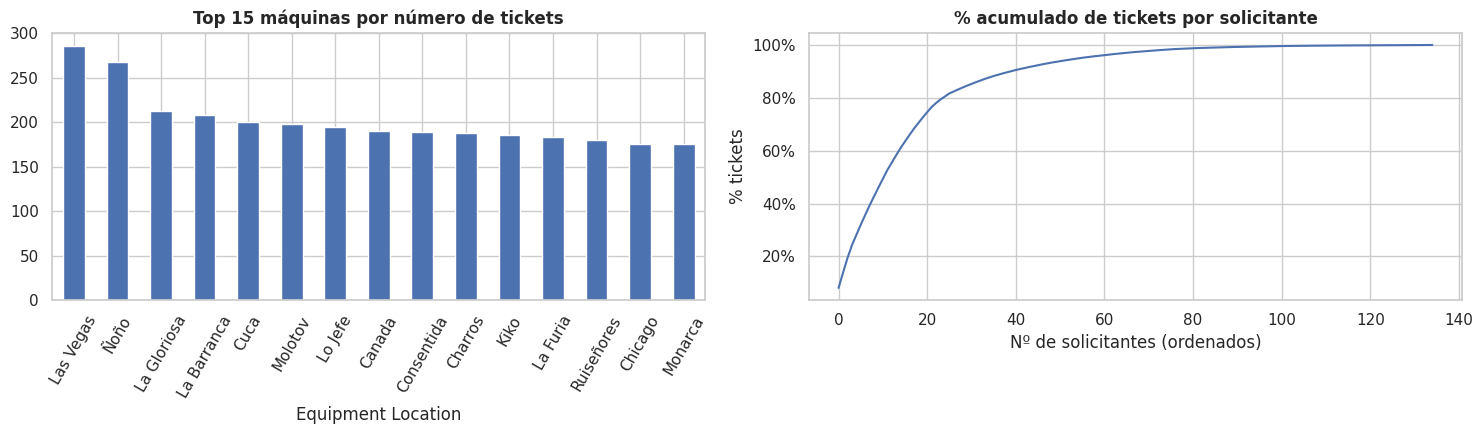

135 solicitantes; los 20 principales abren el 73% de los tickets


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
tk['Equipment Location'].value_counts().head(15).plot.bar(ax=ax[0], color='#4C72B0'); ax[0].set(title='Top 15 máquinas por número de tickets'); ax[0].tick_params(axis='x', rotation=60)
rq = tk['Requested for'].value_counts()
(rq.cumsum()/rq.sum()*100).reset_index(drop=True).plot(ax=ax[1]); ax[1].set(title='% acumulado de tickets por solicitante', xlabel='Nº de solicitantes (ordenados)', ylabel='% tickets'); ax[1].yaxis.set_major_formatter(mtick.PercentFormatter())
plt.tight_layout(); plt.show()
print(f'{len(rq)} solicitantes; los 20 principales abren el {rq.head(20).sum()/rq.sum():.0%} de los tickets')

## 6. Relación entre ambos archivos

In [ ]:
req_dt = set(dt.loc[dt.Con_ticket, 'Ticket'])
req_tk = set(tk['Number'])
print(f'Tickets únicos en Downtime: {len(req_dt):,} | en Tickets: {len(req_tk):,} | en ambos: {len(req_dt & req_tk):,}')
print(f'Tickets de la hoja Data con Downtime>0: {(tk.Downtime>0).mean():.1%}')
print('Eventos de downtime por ticket (tickets repetidos):'); print(dt.loc[dt.Con_ticket, 'Ticket'].value_counts().describe())
m = dt[dt.Con_ticket].merge(tk[['Number','Minor code','Repair Time','Problem Type','texto']], left_on='Ticket', right_on='Number', how='left')
print(f'\nEventos de downtime enlazados a un ticket con texto: {m["texto"].notna().mean():.1%}')

Tickets únicos en Downtime: 4,931 | en Tickets: 11,112 | en ambos: 4,928
Tickets de la hoja Data con Downtime>0: 44.4%
Eventos de downtime por ticket (tickets repetidos):
count   4,931.000
mean        1.701
std         2.275
min         1.000
25%         1.000
50%         1.000
75%         2.000
max       102.000
Name: count, dtype: float64

Eventos de downtime enlazados a un ticket con texto: 100.0%


**Interpretación.** Ambos archivos se pueden **unir por el número de ticket (`REQ-…`)**: 4,928 tickets aparecen en ambos y el 100% de los paros con ticket tienen texto disponible. Un mismo ticket puede tener varios eventos de downtime (hasta 102 en un caso de *LaBarranca*, con 102 microparos eléctricos en 5 días), por lo que al unir se debe agregar a nivel ticket (suma de horas, número de eventos). Esta unión permite construir un dataset que combine **texto + clase + duración del paro**.

## 7. Indicadores de confiabilidad por máquina (MTBF / MTTR)

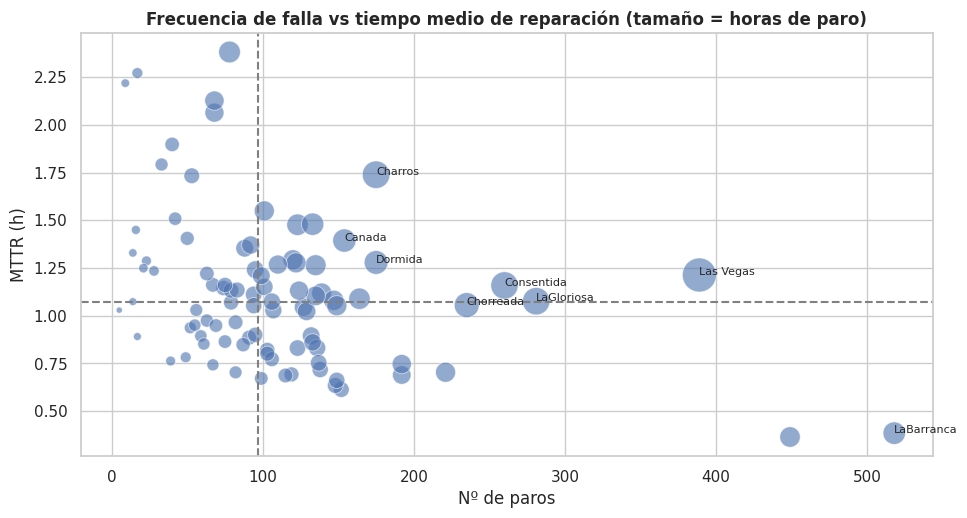

,fallas,horas_paro,MTTR_h,tipo,MTBF_h,Disponibilidad_%
Equipo,,,,,,
Las Vegas,389,472.123,1.214,IMM,35.681,96.710
Charros,175,304.358,1.739,IMM,80.272,97.879
LaGloriosa,281,302.454,1.076,IMM,49.998,97.893
Consentida,260,301.317,1.159,IMM,54.041,97.901
Chorreada,235,248.131,1.056,IMM,60.016,98.271
Dormida,175,223.894,1.279,IMM,80.732,98.440
Canada,154,214.702,1.394,IMM,91.801,98.504
LaBarranca,518,199.404,0.385,IMM,27.322,98.611
Ruisenores,133,196.835,1.480,IMM,106.430,98.629


In [ ]:
dias_periodo = (dt.Opened.max() - dt.Opened.min()).days
rel = dt.groupby('Equipo').agg(fallas=('Downtime_h','count'), horas_paro=('Downtime_h','sum'), MTTR_h=('Downtime_h','mean'),
                                tipo=('Tipo_equipo', lambda s: s.mode().iat[0] if len(s.mode()) else 'NA'))
rel['MTBF_h'] = (dias_periodo*24 - rel['horas_paro']) / rel['fallas']
rel['Disponibilidad_%'] = (1 - rel['horas_paro']/(dias_periodo*24))*100
fig, ax = plt.subplots(figsize=(11, 5.5))
sns.scatterplot(data=rel, x='fallas', y='MTTR_h', size='horas_paro', sizes=(20, 600), alpha=.6, ax=ax, legend=False)
for n, r in rel.nlargest(8, 'horas_paro').iterrows(): ax.annotate(n, (r.fallas, r.MTTR_h), fontsize=8)
ax.axvline(rel.fallas.median(), ls='--', c='gray'); ax.axhline(rel.MTTR_h.median(), ls='--', c='gray')
ax.set(title='Frecuencia de falla vs tiempo medio de reparación (tamaño = horas de paro)', xlabel='Nº de paros', ylabel='MTTR (h)')
plt.show()
rel.sort_values('horas_paro', ascending=False).head(10)

**Interpretación.** El cuadrante superior derecho (muchas fallas **y** alto MTTR) identifica las máquinas críticas: *Las Vegas*, *Charros*, *Consentida*, *LaGloriosa* y *Canada*. *LaBarranca* falla muy seguido pero se recupera rápido (MTBF ≈ 27 h, MTTR ≈ 0.4 h), un patrón típico de microparos recurrentes. La disponibilidad calculada solo considera paros correctivos (no preventivos ni tiempo sin producción), por lo que es una cota superior.

## 8. Correlaciones entre variables numéricas

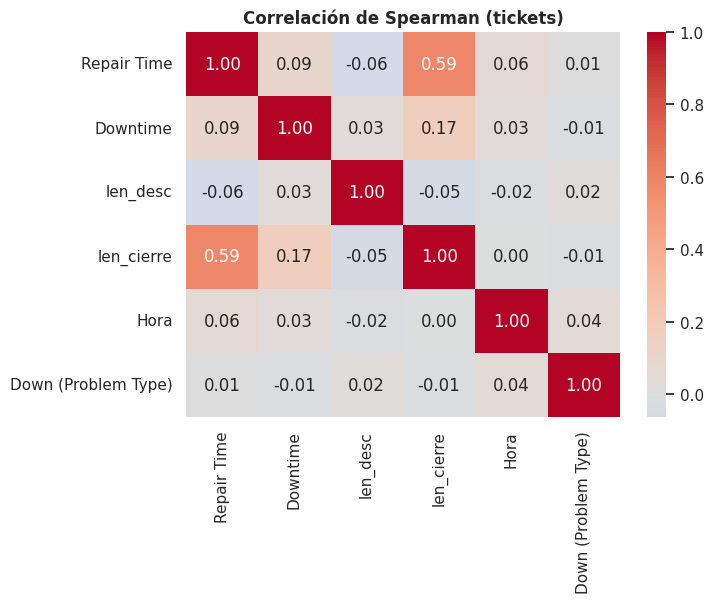

In [ ]:
num = tk[['Repair Time','Downtime','len_desc','len_cierre','Hora']].copy()
num['Down (Problem Type)'] = (tk['Problem Type']=='Down').astype(int)
plt.figure(figsize=(7, 5)); sns.heatmap(num.corr(method='spearman'), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlación de Spearman (tickets)'); plt.show()

**Interpretación.** Las variables numéricas de los tickets tienen correlaciones débiles entre sí. La más alta es entre la **longitud del texto de cierre y el tiempo de reparación (0.59)**: reparaciones más largas se documentan con más detalle, lo que sugiere que el texto puede aportar información para estimar la duración. La hora del día y el tipo Up/Down prácticamente no se relacionan con la duración. Esto indica que para predecir el downtime serán más relevantes las variables categóricas (equipo, máquina, clase de falla, marca) y el texto, que las numéricas disponibles.